# Fase 1 · Carga y verificación del corpus de cánticos

[Inicio del proyecto](../../README.md) · [Marco del proyecto](../../docs/business_understanding/project_charter.md) · [Diccionarios de datos](../../docs/data/data_dictionary.md)

Este cuaderno carga los archivos incluidos en el repositorio y comprueba que el corpus puede usarse en la siguiente fase. Presenta los resultados a partir del recibo que genera el [cargador de Python](main.py).

## 1. Ejecutar la carga

Abra el cuaderno en el entorno de Poetry y ejecute todas las celdas. El cargador lee los ocho archivos de `data/source/` sin conexión a internet. Comprueba las huellas SHA-256, la estructura y los conteos antes de guardar los CSV en `data/raw/` y escribir el recibo en `data/carga_fase1.json`.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

from IPython.display import Markdown, display

directorio_actual = Path.cwd().resolve()
raiz = next(
    (
        directorio
        for directorio in (directorio_actual, *directorio_actual.parents)
        if (directorio / "pyproject.toml").is_file()
        and (directorio / "scripts/data_acquisition/main.py").is_file()
    ),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abra este cuaderno desde el repositorio del proyecto.")

try:
    subprocess.run(
        [sys.executable, str(raiz / "scripts/data_acquisition/main.py")],
        cwd=raiz,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    detalle = error.stderr.strip().replace(str(raiz), ".")
    raise RuntimeError(detalle or "El cargador no terminó correctamente.") from None

ruta_recibo = raiz / "data/carga_fase1.json"
recibo = json.loads(ruta_recibo.read_text(encoding="utf-8"))
controles = recibo["controles"]

display(
    Markdown(
        f"**Versión de los datos** `{recibo['version']}` · "
        f"**Corte de adquisición** `{recibo['fecha_corte']}`"
    )
)

**Versión de los datos** `fase1-2026-09-01` · **Corte de adquisición** `2026-09-01`

## 2. Inventario verificado

El corpus y el registro de clubes son la entrada principal del análisis. Las demás tablas documentan cobertura, procedencia, referencias y decisiones de revisión.

In [2]:
import pandas as pd

inventario = pd.DataFrame(
    [
        {"Archivo": nombre, "Filas": ficha["filas"], "Columnas": ficha["columnas"]}
        for nombre, ficha in recibo["archivos"].items()
    ]
).set_index("Archivo")
display(inventario)

,Filas,Columnas
Archivo,,
canticos.csv,600,19
clubes.csv,20,30
control_cobertura.csv,20,8
duplicados_exactos.csv,10,8
fuentes_revisadas.csv,31,8
cambios_identidad_clubes.csv,2,8
bibliografia_apa7.csv,75,6
decisiones_revision_fase2.csv,57,14


## 3. Distribución por fuente

Cada barra mide el número de cánticos adquiridos en una fuente. La mayor concentración en Barrabrava.net describe la composición del corpus. Para comparar clubes en las fases siguientes, habrá que considerar qué fuentes aportaron sus textos.

,Registros,Porcentaje
Fuente,,
Barrabrava.net,388,"64,7 %"
FanChants,176,"29,3 %"
Blog Attake Massivo Pasto & La Banda Tricolor,18,"3,0 %"
Fortaleza Leoparda (4mg),18,"3,0 %"


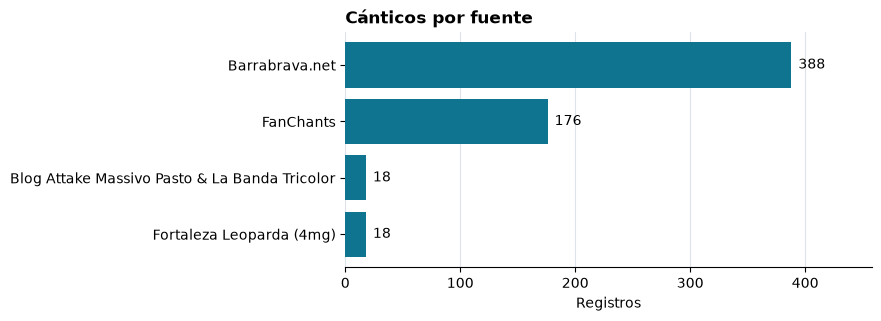

In [3]:
import matplotlib.pyplot as plt

total_canticos = controles["canticos"]


def tabla_conteos(conteos, nombre_indice):
    tabla = pd.Series(conteos, name="Registros").rename_axis(nombre_indice).to_frame()
    tabla["Porcentaje"] = tabla["Registros"].map(
        lambda cantidad: f"{100 * cantidad / total_canticos:.1f}".replace(".", ",") + " %"
    )
    return tabla


fuentes = tabla_conteos(controles["canticos_por_fuente"], "Fuente")
display(fuentes)

figura, eje = plt.subplots(figsize=(8.7, 3.1), layout="constrained")
barras = eje.barh(fuentes.index, fuentes["Registros"], color="#0E7490")
eje.invert_yaxis()
eje.set_xlim(0, fuentes["Registros"].max() * 1.18)
eje.bar_label(barras, padding=5)
eje.set_xlabel("Registros")
eje.set_title("Cánticos por fuente", loc="left", fontweight="bold")
eje.spines[["top", "right", "left"]].set_visible(False)
eje.set_axisbelow(True)
eje.grid(axis="x", color="#CBD5E1", alpha=0.65)
plt.show()

## 4. Cobertura y calidad de la adquisición

El estado de verificación registra decisiones y banderas de calidad de las fuentes. Los casos señalados siguen presentes en la adquisición y se revisarán en la fase de preprocesamiento.

In [4]:
clubes_con_textos = controles["clubes_con_textos"]
clubes_referencia = controles["clubes_referencia"]
clubes_sin_textos = controles["clubes_sin_textos_localizados"]
palabras = format(controles["palabras"], ",").replace(",", ".")

assert sum(controles["canticos_por_fuente"].values()) == total_canticos
assert sum(controles["estados_verificacion"].values()) == total_canticos
assert clubes_con_textos + len(clubes_sin_textos) == clubes_referencia

display(
    Markdown(
        f"| Cánticos | Clubes con textos | Palabras declaradas | Duplicados exactos documentados |\n"
        f"| ---: | ---: | ---: | ---: |\n"
        f"| {total_canticos} | {clubes_con_textos} de {clubes_referencia} | "
        f"{palabras} | {controles['duplicados_exactos_documentados']} |\n\n"
        f"**Clubes sin textos localizados en el corte** · {', '.join(clubes_sin_textos)}"
    )
)
display(tabla_conteos(controles["estados_verificacion"], "Estado de verificación"))

| Cánticos | Clubes con textos | Palabras declaradas | Duplicados exactos documentados |
| ---: | ---: | ---: | ---: |
| 600 | 17 de 20 | 33.077 | 10 |

**Clubes sin textos localizados en el corte** · Águilas Doradas, Fortaleza CEIF, Llaneros FC

,Registros,Porcentaje
Estado de verificación,,
aceptado,512,"85,3 %"
requiere revisión: similitud,67,"11,2 %"
requiere revisión: segmentación de fuente,18,"3,0 %"
requiere revisión: asociación con club,3,"0,5 %"


## Lectura para la fase siguiente

La cobertura indica cuántos clubes tienen textos en las fuentes consultadas. La ausencia de un club en el corpus es un límite de la búsqueda documentada. Las banderas orientan la curaduría de similitud, segmentación y asociación con clubes. La preparación lingüística se hará sobre una copia de trabajo, conservando las letras de adquisición.

La [definición de los datos](../../docs/data/data_definition.md) explica la procedencia y los controles del corte.